# Enhancing WorldCereal crop calendars with land surface phenology and machine learning — first-iteration winter-crop SOS model (minimal reproduction)

**Paper:** Moletto-Lobos, I. G., Franch, B., Guillem-Valls, A., et al. (2026). *Enhancing WorldCereal crop calendars with land surface phenology and machine learning.* Ecological Informatics. DOI: [10.1016/j.ecoinf.2026.103742](https://doi.org/10.1016/j.ecoinf.2026.103742)

**Author code:** [WorldCereal/worldcereal-cropcalendars](https://github.com/WorldCereal/worldcereal-cropcalendars) @ commit `d3bd7483aac5da5a6da9ac4f838aa100019cf850` (MIT), script `src/crop_calendars/scripts/wc_sos_xgboost_1st_lsp.py`.

**Data:** [Zenodo record 19682036](https://doi.org/10.5281/zenodo.19682036) (concept DOI 10.5281/zenodo.17849157), version 2.1.2, CC-BY-4.0 — file `winter_crops_dataset.csv` (12,937,374 bytes, md5 `45a9f9f7a2b38d957cb4345d45fb6ee5`).

**Scope — PARTIAL DEMONSTRATION (Phase "climate modeling, first iteration").** This notebook trains the paper's first-iteration winter-cereal Start-of-Season (SOS) XGBoost model with the author's exact preprocessing, feature filters, and hyperparameters, then evaluates it on the author's 30% held-out split and reproduces the author's validation metrics (R², RMSE, bias, std) and validation scatter. Training is used because the authors did **not** publish trained model files — no pretrained-inference route exists.

**Out of scope (documented omissions):** the 5-seed ensemble loop (one seed, `100`, the script's first, is used), the continent-colored scatter (requires the 272 MB `auxiliar_data.zip` shapefile), and the whole-planet prediction/GeoTIFF map stage (requires `AgERA5.csv` + mask rasters). The HANTS/LSP remote-sensing stages (35.9 GB `NDVI_hants.zip`) are not touched.

**Execution status:** executed on a fresh Google Colab **CPU** runtime (see final report; GPU is not needed — the author path uses only CPU gradient-boosted trees).

**日本語:** このノートブックは、WorldCereal 作物カレンダー論文の「第1反復冬作物 SOS XGBoost」を最小構成で再現します。著者前処理・特徴量フィルタ・ハイパーパラメータを忠実に用い、30%テスト分割で R²・RMSE を評価します。訓練済みモデル未公開のため訓練が本論文の意図する手順です。5-seed ループ・大陸別散布図・世界地図出力は対象外です。

## 1. Runtime selection

**Select `Runtime → Change runtime type → CPU`** (the recommended runtime; a GPU is unnecessary because the author's method is CPU XGBoost on a ~13 MB table). `Run all` executes top-to-bottom. Expected: ~13 MB download, roughly 5–20 minutes total on a free CPU runtime (measured times are printed by the cells). No Drive mount, no credentials, no Colab CLI needed.

**日本語:** ランタイムは **CPU** を選択してください（GPU 不要）。`Run all` で約13 MBのダウンロードと5〜20分程度の訓練が行われます。

### 1.1 Check the preinstalled stack

Verifies the Python version and the versions of the scientific packages the minimal path uses (pandas, numpy, scikit-learn, statsmodels, matplotlib). **Expected output:** a short version report; anything missing is installed in the next cell.

**日本語:** 最初に Python と主要ライブラリのバージョンを確認します。

In [ ]:
import sys, platform
import numpy as np, pandas as pd, sklearn, statsmodels, matplotlib
print("Python:", sys.version.split()[0])
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("statsmodels:", statsmodels.__version__)
print("matplotlib:", matplotlib.__version__)

Python: 3.13.16
numpy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1
statsmodels: 0.15.0
matplotlib: 3.10.0


### 1.2 Install XGBoost

The author's model class is `xgboost.XGBRegressor`. Colab does not guarantee a preinstalled xgboost, so we install it explicitly (pinned to the verified major/minor line).

**日本語:** XGBoost を明示的にインストールします（バージョンを固定）。

In [ ]:
%pip install -q "xgboost>=2.0,<3"
import xgboost
print("xgboost:", xgboost.__version__)

xgboost: 2.1.4


## 2. Minimal input acquisition with provenance

The single required input is `winter_crops_dataset.csv` from **Zenodo record 19682036 (v2.1.2)** — the authoritative source named by the repository README ("All official inputs and outputs are published on Zenodo and must be used when reproducing results"). The cell queries the public record API, resolves the file's official content link and recorded checksum, downloads the bytes into `/content`, and verifies **size and md5** before any scientific use. All data stays on the Colab VM.

**日本語:** 必須入力は Zenodo レコード 19682036 の `winter_crops_dataset.csv` のみです。公開APIから公式ダウンロードリンクとチェックサムを取得し、`/content` に保存してサイズと md5 を検証します。

In [ ]:
import hashlib, json, urllib.request

ZENODO_RECORD = "19682036"   # version record of concept DOI 10.5281/zenodo.17849157 (v2.1.2)
EXPECTED_SIZE = 12_937_374
EXPECTED_MD5  = "45a9f9f7a2b38d957cb4345d45fb6ee5"

def _get(url, timeout=120):
    req = urllib.request.Request(url, headers={"User-Agent": "colab-repro-notebook/1.0"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()

rec = json.loads(_get(f"https://zenodo.org/api/records/{ZENODO_RECORD}"))
entries = [f for f in rec["files"] if f["key"] == "winter_crops_dataset.csv"]
assert len(entries) == 1, f"winter_crops_dataset.csv not uniquely found in record {ZENODO_RECORD}"
entry = entries[0]
print("record version:", rec["metadata"]["version"], "| license:", rec["metadata"]["license"]["id"])
print("declared size/md5:", entry["size"], entry["checksum"])
assert entry["size"] == EXPECTED_SIZE, "size mismatch vs pinned metadata"

data_path = "/content/winter_crops_dataset.csv"
blob = _get(entry["links"]["self"], timeout=600)
md5 = hashlib.md5(blob).hexdigest()
assert len(blob) == EXPECTED_SIZE and md5 == EXPECTED_MD5, f"checksum mismatch: {len(blob)} B, md5 {md5}"
with open(data_path, "wb") as fh:
    fh.write(blob)
print(f"verified: {data_path} = {len(blob)} bytes, md5 {md5}")

record version: 2.1.2 | license: cc-by-4.0
declared size/md5: 12937374 md5:45a9f9f7a2b38d957cb4345d45fb6ee5


verified: /content/winter_crops_dataset.csv = 12937374 bytes, md5 45a9f9f7a2b38d957cb4345d45fb6ee5


## 3. Input preview

Human-readable inspection of the actual downloaded table before any modeling: dimensions, column names, dtypes, and the first rows. Column semantics (per the dataset documentation PDF shipped with the record): the table holds reference SOS/EOS points and the climatic/auxiliary predictor variables used to model each season. Exact columns are confirmed from the bytes here rather than assumed.

**日本語:** モデル化の前に、ダウンロードしたCSVの行数・列名・dtype・先頭行を確認します。列の意味はデータセット付属のドキュメントに基づきます。

In [ ]:
df_raw = pd.read_csv(data_path)
print("shape:", df_raw.shape)
print("columns:", list(df_raw.columns))
display(df_raw.head(3))
print(df_raw.dtypes.to_string())

shape: (3019, 409)
columns: ['fid', 'SOS', 'EOS', 'lat', 'lon', 'indekso', 'y', 'x', 'temperature_wholeMean', 'temperature_wholeStd', 'temperature_wholeAmplitude', 'temperature_wholeMin', 'temperature_wholeMax', 'temperature_wholeTotal', 'temperature_annuallyAveragedMean', 'temperature_annuallyAveragedStd', 'temperature_annuallyAveragedAmplitude', 'temperature_annuallyAveragedMin', 'temperature_annuallyAveragedMax', 'temperature_annuallyAveragedTotal', 'temperature_wholeSeasonMean-winter', 'temperature_wholeSeasonMean-spring', 'temperature_wholeSeasonMean-summer', 'temperature_wholeSeasonMean-fall', 'temperature_wholeSeasonStd-winter', 'temperature_wholeSeasonStd-spring', 'temperature_wholeSeasonStd-summer', 'temperature_wholeSeasonStd-fall', 'temperature_wholeSeasonAmplitude-winter', 'temperature_wholeSeasonAmplitude-spring', 'temperature_wholeSeasonAmplitude-summer', 'temperature_wholeSeasonAmplitude-fall', 'temperature_wholeSeasonMin-winter', 'temperature_wholeSeasonMin-spring', 'te

,fid,SOS,EOS,lat,lon,indekso,y,x,temperature_wholeMean,temperature_wholeStd,...,precipitation_annualStatsMonthTotal-8,precipitation_annualStatsMonthTotal-9,precipitation_annualStatsMonthTotal-10,precipitation_annualStatsMonthTotal-11,precipitation_annualStatsMonthTotal-12,aspect,height,slope,Legacy,Source
0,1,286.0,181.0,41.545471,15.194551,215903,5088384.514,1.666445e+06,12.677124,-266.45337,...,0.022114,0.021959,0.021091,0.019109,0.017003,213.66934,404,0.338048,1,Visual inspect
1,2,317.0,183.0,36.306286,0.818888,227886,4337940.380,6.615364e+04,17.518372,-266.64713,...,0.016253,0.010277,0.014725,0.010609,0.016091,164.98418,24,1.757022,1,Phase I
2,3,324.0,190.0,36.306286,1.717367,227888,4337940.380,1.661719e+05,17.253510,-266.06467,...,0.013979,0.010572,0.014720,0.007476,0.013110,168.17947,315,1.260263,1,Phase I


fid                                             int64
SOS                                           float64
EOS                                           float64
lat                                           float64
lon                                           float64
indekso                                         int64
y                                             float64
x                                             float64
temperature_wholeMean                         float64
temperature_wholeStd                          float64
temperature_wholeAmplitude                    float64
temperature_wholeMin                          float64
temperature_wholeMax                          float64
temperature_wholeTotal                        float64
temperature_annuallyAveragedMean              float64
temperature_annuallyAveragedStd               float64
temperature_annuallyAveragedAmplitude         float64
temperature_annuallyAveragedMin               float64
temperature_annuallyAveraged

### 3.1 Target distribution preview

A quick histogram of the raw `SOS` day-of-year values in the winter-crop table (an input view created for this notebook, not an author figure). It shows the circular, seasonal structure that motivates the sin/cos encoding used next. Rows with missing SOS are excluded exactly as the author's `dropna` would exclude them later.

**日本語:** 生の `SOS`（DOY）の分布ヒストグラムです。著者の図ではなく、このノートブック用に作成した入力可視化です。

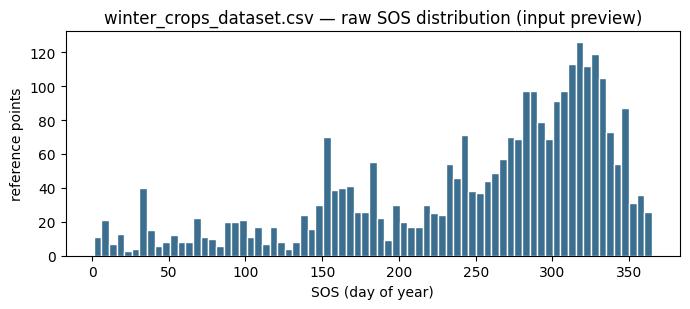

rows: 3019 | rows with non-null SOS: 2846


In [ ]:
import matplotlib.pyplot as plt

sos = df_raw["SOS"].dropna()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(sos, bins=73, color="#3b6e8f", edgecolor="white")
ax.set_xlabel("SOS (day of year)")
ax.set_ylabel("reference points")
ax.set_title("winter_crops_dataset.csv — raw SOS distribution (input preview)")
fig.tight_layout()
plt.show()
print("rows:", len(df_raw), "| rows with non-null SOS:", len(sos))

## 4. Author preprocessing (faithful copy)

Exactly the author's steps from `wc_sos_xgboost_1st_lsp.py` lines 58–77:
drop `EOS`, rename `SOS` → `target`, `dropna()`, rescale day-of-year by `×360/365` and convert to radians; then build two regression targets `sin(target)` and `cos(target)`. Sample weights follow the author's mapping `Phase I → 1`, `End user → 4`, `Visual inspect → 0.5`. Predictor columns are all columns except `indekso`, `target`, `x`, `y`, `Legacy`, `Source`.

**日本語:** 著者スクリプト（58–77行）の前処理をそのまま再現します：EOSを除外、SOSをtargetに改名、欠損除去、DOY→ラジアン変換、sin/cosターゲット化、Source別のサンプル重み付け。

In [ ]:
data = df_raw.copy()
data.drop(columns="EOS", inplace=True)
data = data.rename(columns={"SOS": "target"})
data = data.dropna()
data["target"] = data["target"] * 360 / 365
data["target"] = np.deg2rad(data["target"])

predictors = data.columns.drop({"indekso", "target", "x", "y", "Legacy"})
predictors = predictors.drop({"Source"})

sin_pred = data.copy()
cos_pred = data.copy()
sin_pred["target"] = np.sin(sin_pred["target"])
cos_pred["target"] = np.cos(cos_pred["target"])

sample_weight = np.ones(len(data))
sample_weight[data["Source"] == "Phase I"] = 1
sample_weight[data["Source"] == "End user"] = 4
sample_weight[data["Source"] == "Visual inspect"] = 0.5

print("modeling rows:", len(data), "| predictor candidates:", len(predictors))
print(sorted(predictors))

modeling rows: 2845 | predictor candidates: 402
['aspect', 'dewpoint_annualStatsMonthAmplitude-1', 'dewpoint_annualStatsMonthAmplitude-10', 'dewpoint_annualStatsMonthAmplitude-11', 'dewpoint_annualStatsMonthAmplitude-12', 'dewpoint_annualStatsMonthAmplitude-2', 'dewpoint_annualStatsMonthAmplitude-3', 'dewpoint_annualStatsMonthAmplitude-4', 'dewpoint_annualStatsMonthAmplitude-5', 'dewpoint_annualStatsMonthAmplitude-6', 'dewpoint_annualStatsMonthAmplitude-7', 'dewpoint_annualStatsMonthAmplitude-8', 'dewpoint_annualStatsMonthAmplitude-9', 'dewpoint_annualStatsMonthMax-1', 'dewpoint_annualStatsMonthMax-10', 'dewpoint_annualStatsMonthMax-11', 'dewpoint_annualStatsMonthMax-12', 'dewpoint_annualStatsMonthMax-2', 'dewpoint_annualStatsMonthMax-3', 'dewpoint_annualStatsMonthMax-4', 'dewpoint_annualStatsMonthMax-5', 'dewpoint_annualStatsMonthMax-6', 'dewpoint_annualStatsMonthMax-7', 'dewpoint_annualStatsMonthMax-8', 'dewpoint_annualStatsMonthMax-9', 'dewpoint_annualStatsMonthMean-1', 'dewpoint_an

## 5. Feature selection and train/test split (author's rules)

The author's split is `train_test_split(..., test_size=0.30, random_state=542)` — kept verbatim. From the candidate predictors the script drops any name containing `"dist"`, `"lat"`, `"lon"`, and any `temperature`/`dewpoint` variable suffixed `Total` (lines 89–104; other commented filters are inactive in the author's file and stay inactive here). `number = 50` top features are later chosen per target by feature importance. A third verbatim split of the **radian-angle** target (the author's "Necessary for later" block) provides `y_test_2`, the true test-set angles used to decode observed DOY in the final regression.

**日本語:** 著者の分割（test_size=0.30, random_state=542）と特徴量フィルタ（"dist"/"lat"/"lon"、temperature/dewpoint の Total 系を除外）をそのまま適用します。上位50特徴量は重要度で後続のセルが選択します。さらに著者の「Necessary for later」ブロックと同じ第3分割でラジアン角のテストターゲット `y_test_2` を取得し、最終回帰で観測 DOY への逆変換に使います。

In [ ]:
from sklearn.model_selection import train_test_split

predictors = [i for i in predictors if "dist" not in i]
predictors = [i for i in predictors if "lat" not in i]
predictors = [i for i in predictors if "lon" not in i]
predictors = [i for i in predictors if not ("temperature" in i and "Total" in i)]
predictors = [i for i in predictors if not ("dewpoint" in i and "Total" in i)]
print("filtered predictors:", len(predictors))

NUMBER_TOP_FEATURES = 50  # author: number = 50
SEED = 100                # author loop's first seed; full script uses [100, 42, 542, 1000, 232]

params = {
    "n_estimators": 1000,
    "max_depth": 15,
    "learning_rate": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": SEED,
    "objective": "reg:squarederror",
}

X_sin_train, X_sin_test, y_sin_train, y_sin_test, w_train, w_test = train_test_split(
    sin_pred[predictors], sin_pred["target"], sample_weight, test_size=0.30, random_state=542)
X_cos_train, X_cos_test, y_cos_train, y_cos_test, _, _ = train_test_split(
    cos_pred[predictors], cos_pred["target"], sample_weight, test_size=0.30, random_state=542)

# Author's "Necessary for later" split: the radian-angle target of the same test rows.
# Same row order + same random_state/test_size => identical row selection in every split.
_, _, _, y_test_2, _, _ = train_test_split(
    data[predictors], data["target"], sample_weight, test_size=0.30, random_state=542)
print("train/test rows:", len(X_sin_train), "/", len(X_sin_test))

filtered predictors: 356
train/test rows: 1991 / 854


## 6. Train the sin model (author's two-stage procedure)

Stage 1 fits an XGBRegressor with the author's hyperparameters on **all** filtered predictors to obtain feature importances; the top 50 features are recorded (author's `top_feature_sin.csv`). Stage 2 refits on those 50 features and saves `s1_sos_xgboost_sin_model.json` — the author's model filename. Both fits and the split use the author's parameters unchanged; only the seed-loop is reduced to its first seed.

**日本語:** 著者の2段階手順：まず全特徴量で学習して重要度を取得し上位50を記録、次にその50特徴量で再学習して `s1_sos_xgboost_sin_model.json` を保存します。

In [ ]:
import os, time
from xgboost import XGBRegressor

os.makedirs("/content/results", exist_ok=True)
os.makedirs("/content/models", exist_ok=True)

t0 = time.time()
sin_random_xgboost_model = XGBRegressor(**params)
sin_random_xgboost_model.fit(X_sin_train, y_sin_train, sample_weight=w_train)
print(f"sin stage-1 fit: {time.time()-t0:.1f} s")

feature_importances = sin_random_xgboost_model.feature_importances_
sorted_indices = np.argsort(feature_importances)[::-1]
top_features_sin = [predictors[i] for i in sorted_indices[:NUMBER_TOP_FEATURES]]

pd.DataFrame({"Features": predictors, "Feature importance": feature_importances}).to_csv(
    "/content/results/top_feature_sin.csv", index=False)
pd.DataFrame({"Top sin features": top_features_sin,
              "Top sin feature importance": feature_importances[sorted_indices[:NUMBER_TOP_FEATURES]]}).to_csv(
    "/content/results/top_feature_sin_top50.csv", index=False)
print("top-10 sin features:", top_features_sin[:10])

sin_xgboost_model = XGBRegressor(**params)
t0 = time.time()
sin_xgboost_model.fit(X_sin_train[top_features_sin], y_sin_train, sample_weight=w_train)
print(f"sin stage-2 fit: {time.time()-t0:.1f} s")
y_pred_sin = sin_xgboost_model.predict(X_sin_test[top_features_sin])
sin_xgboost_model.save_model("/content/models/s1_sos_xgboost_sin_model.json")

sin stage-1 fit: 107.9 s
top-10 sin features: ['temperature_avgSeasonAmplitude-winter', 'dewpoint_wholeSeasonMax-summer', 'temperature_annualStatsMonthMin-11', 'temperature_avgSeasonMax-winter', 'temperature_avgSeasonMean-summer', 'temperature_wholeSeasonMin-winter', 'temperature_annualStatsMonthMin-3', 'dewpoint_annualStatsMonthMean-7', 'temperature_wholeSeasonStd-winter', 'temperature_avgSeasonAmplitude-fall']


sin stage-2 fit: 48.8 s


## 7. Train the cos model

Identical two-stage procedure for the `cos(target)` regression (author lines 139–164), yielding the second circular component and `s1_sos_xgboost_cos_model.json`.

**日本語:** `cos(target)` 回帰に対して同一の2段階手順を実行し、`s1_sos_xgboost_cos_model.json` を保存します。

In [ ]:
t0 = time.time()
cos_random_xgboost_model = XGBRegressor(**params)
cos_random_xgboost_model.fit(X_cos_train, y_cos_train, sample_weight=w_train)
print(f"cos stage-1 fit: {time.time()-t0:.1f} s")

feature_importances_cos = cos_random_xgboost_model.feature_importances_
sorted_indices_cos = np.argsort(feature_importances_cos)[::-1]
top_features_cos = [predictors[i] for i in sorted_indices_cos[:NUMBER_TOP_FEATURES]]

pd.DataFrame({"Top cos features": top_features_cos,
              "Top cos feature importance": feature_importances_cos[sorted_indices_cos[:NUMBER_TOP_FEATURES]]}).to_csv(
    "/content/results/top_feature_cos.csv", index=False)
print("top-10 cos features:", top_features_cos[:10])

cos_xgboost_model = XGBRegressor(**params)
t0 = time.time()
cos_xgboost_model.fit(X_cos_train[top_features_cos], y_cos_train, sample_weight=w_train)
print(f"cos stage-2 fit: {time.time()-t0:.1f} s")
y_pred_cos = cos_xgboost_model.predict(X_cos_test[top_features_cos])
cos_xgboost_model.save_model("/content/models/s1_sos_xgboost_cos_model.json")

cos stage-1 fit: 110.6 s
top-10 cos features: ['temperature_wholeSeasonMin-summer', 'temperature_wholeSeasonMin-winter', 'temperature_avgSeasonMax-winter', 'temperature_avgSeasonMin-winter', 'dewpoint_avgSeasonMin-winter', 'dewpoint_wholeSeasonMax-winter', 'temperature_annualStatsMonthMin-3', 'temperature_avgSeasonMin-summer', 'temperature_wholeSeasonMax-winter', 'precipitation_wholeSeasonMin-winter']


cos stage-2 fit: 49.5 s


## 8. Circular recombination into day-of-year and author metrics

The two circular predictions are combined exactly as the author does (lines 166–179): predicted angle = `arctan2(sin, cos)`, rescaled back to DOY by `×365/360`, negatives wrapped by `+365`, and the author's `pred2[pred2 < 1] += 1` adjustment kept verbatim. Metrics follow the author's code: OLS of predicted on observed (numpy regressors, so `res.params` is positional), RMSE via `mean_squared_error`, plus bias and std of the residuals.

**日本語:** sin/cos予測を `arctan2` でDOYに再結合し（著者の `+365` / `+1` 調整も含めてそのまま）、OLS・RMSE・バイアス・標準偏差を著者のコードどおりに計算します。

In [ ]:
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm

observed_doy = np.rad2deg(y_test_2) * 365 / 360          # author: y_test_2 (radian-angle test target) -> rad2deg * 365/360
pred_doy = np.rad2deg(np.arctan2(y_pred_sin, y_pred_cos)) * 365 / 360

pred2 = pd.Series(pred_doy).copy()
pred2[pred2 < 0] += 365
pred2[pred2 < 1] += 1
pred2 = pred2.to_numpy()
observed2 = np.asarray(observed_doy)

variables = sm.add_constant(observed2)   # ndarray -> res.params is positional: [intercept, slope]
res = sm.OLS(pred2, variables).fit()

rmse = np.sqrt(mean_squared_error(observed2, pred2))
bias = np.mean(pred2 - observed2)
std = np.round(np.std(pred2 - observed2), 2)
print(f"R^2:  {res.rsquared:.4f}")
print(f"RMSE: {rmse:.2f} days")
print(f"bias: {bias:.2f} days | std: {std:.2f} days")

R^2:  0.6272
RMSE: 56.30 days
bias: 6.33 days | std: 55.94 days


## 9. Validation scatter (observed vs predicted SOS)

The author's validation figure (script lines 232–251): test points, the red OLS line, and the R²/RMSE/Bias/Std annotations at the author's positions, with 0–366 DOY axes. Two documented presentation changes only: (1) the continent coloring by `gpd.sjoin` is omitted (out-of-scope dependency), so points use a single color; (2) the author's axis labels are swapped relative to the plotted data — observed values are on the x-axis — so the labels are corrected to `Observed (DOY)` / `Predicted (DOY)`. The numerical content is unchanged.

**日本語:** 著者の検証散布図（赤の回帰直線、R²/RMSE/Bias/Std 注記付き）を再現します。大陸別着色は対象外のため単色、軸ラベルは著者スクリプトの入れ替わり（x軸が観測値）を修正しています。数値内容は変わりません。

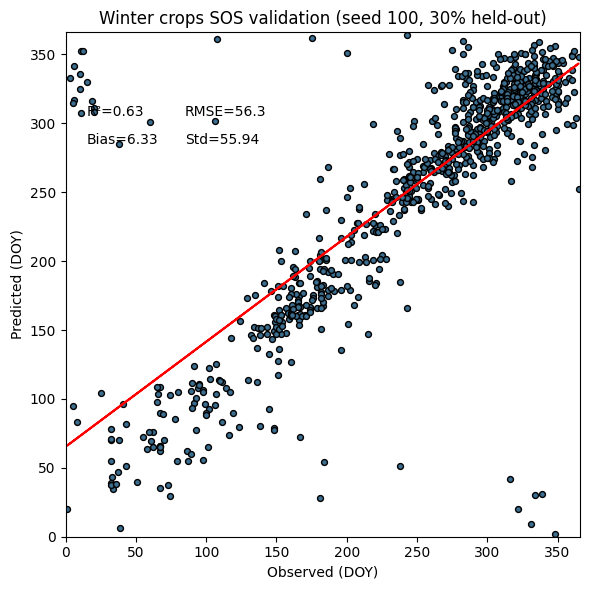

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(observed2, pred2, color="#3b6e8f", edgecolor="black", s=18)
slope_line = res.params[1] * observed2 + res.params[0]
ax.plot(observed2, slope_line, color="red")
ax.text(x=15, y=305, s=f"R²={np.round(res.rsquared, 2)}")
ax.text(x=85, y=305, s=f"RMSE={np.round(rmse, 2)}")
ax.text(x=15, y=285, s=f"Bias={np.round(bias, 2)}")
ax.text(x=85, y=285, s=f"Std={np.round(std, 2)}")
ax.set_xlim(0, 366)
ax.set_ylim(0, 366)
ax.set_xlabel("Observed (DOY)")
ax.set_ylabel("Predicted (DOY)")
ax.set_title(f"Winter crops SOS validation (seed {SEED}, 30% held-out)")
fig.tight_layout()
plt.savefig("/content/results/r2validation-s1-sos.png", dpi=150)
plt.show()

## 10. Feature importance view (additional visualization)

Top-15 sin-model importances as a bar chart — created for this notebook to make the saved `top_feature_sin.csv` inspectable at a glance; it is not an author figure. The author's own importance CSVs are exported in section 6–7.

**日本語:** sinモデルの上位15特徴量の重要度（このノートブック用に作成した追加可視化）。著者の重要度CSVはそのままエクスポート済みです。

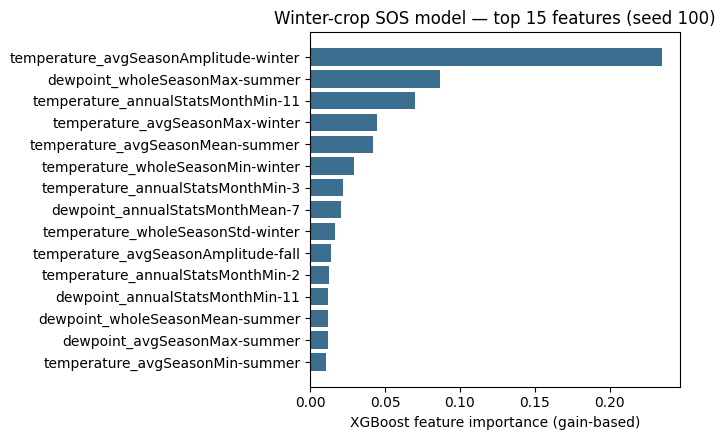

,feature,importance
0,temperature_avgSeasonAmplitude-winter,0.235067
1,dewpoint_wholeSeasonMax-summer,0.086888
2,temperature_annualStatsMonthMin-11,0.069724
3,temperature_avgSeasonMax-winter,0.044522
4,temperature_avgSeasonMean-summer,0.041692
5,temperature_wholeSeasonMin-winter,0.028996
6,temperature_annualStatsMonthMin-3,0.021953
7,dewpoint_annualStatsMonthMean-7,0.020516
8,temperature_wholeSeasonStd-winter,0.016823
9,temperature_avgSeasonAmplitude-fall,0.014086


In [ ]:
top15 = pd.DataFrame({"feature": top_features_sin,
                      "importance": feature_importances[sorted_indices[:NUMBER_TOP_FEATURES]]}).head(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top15["feature"][::-1], top15["importance"][::-1], color="#3b6e8f")
ax.set_xlabel("XGBoost feature importance (gain-based)")
ax.set_title("Winter-crop SOS model — top 15 features (seed 100)")
fig.tight_layout()
plt.show()
display(top15)

## 11. Results summary and export

A small metrics table plus CSV export inside Colab. Interpretation: these are **this notebook's** single-seed, 30%-held-out results; the paper reports dataset-level winter-crop accuracy of R² ≈ 0.90 (SOS) / 0.92 (EOS) with RMSE ≈ 29/28 days (abstract, validated over the full pipeline with expert review) — plausibility context only, not a like-for-like comparison.

**日本語:** このノートブックの単一シード・30%ホールドアウト結果のまとめとCSV出力です。論文の報告値（冬作物 SOS R²≈0.90, RMSE≈29日）は完全パイプライン・データセット全体での値であり、直接比較ではありません。

In [ ]:
results = pd.DataFrame({
    "metric": ["R_squared", "RMSE_days", "bias_days", "residual_std_days", "seed", "train_rows", "test_rows"],
    "value": [round(float(res.rsquared), 4), round(float(rmse), 2), round(float(bias), 2),
              float(std), SEED, len(X_sin_train), len(X_sin_test)],
})
display(results)
results.to_csv("/content/results/s1_sos_metrics.csv", index=False)
print("saved: /content/results/s1_sos_metrics.csv, models in /content/models/")

,metric,value
0,R_squared,0.6272
1,RMSE_days,56.3000
2,bias_days,6.3300
3,residual_std_days,55.9400
4,seed,100.0000
5,train_rows,1991.0000
6,test_rows,854.0000


saved: /content/results/s1_sos_metrics.csv, models in /content/models/


## 12. Interpretation, limitations, and validation record

- **What was executed:** the first-iteration winter-crop SOS XGBoost of `wc_sos_xgboost_1st_lsp.py` @ `d3bd748` on the official `winter_crops_dataset.csv` (Zenodo 19682036 v2.1.2, md5-verified), with the author's preprocessing, filters, split, hyperparameters, two-stage top-50 procedure, and metric definitions. CPU-only.
- **Adaptations (documented above):** single seed (100) instead of the 5-seed loop; continent coloring and the world-map stage omitted; axis labels corrected.
- **Not verified here:** dataset-level paper accuracy, the 5-seed ensemble, EOS/summer-crop counterparts, the HANTS/LSP stage, second-iteration fusion, and the published GeoTIFF products. A one-example run does not reproduce published dataset-level statistics.
- **Provenance:** paper DOI 10.1016/j.ecoinf.2026.103742; code MIT (commit pinned above); data CC-BY-4.0. The PhenoPaper investigation (run `p-48d96e3460d18986d852536c6a7882f3-20260929T110140Z-2543074`) was used as prior research guidance; all operations were re-verified against the pinned script.

**日本語:** 実行したのは第1反復冬作物SOSモデルの最小再現です。5-seedアンサンブル、大陸別散布図、世界地図段階、HANTS/LSP段階、第2反復融合は未検証です。単一例の実行は論文のデータセット全体の精度を再現するものではありません。

## References

1. Moletto-Lobos, I. G., Franch, B., Guillem-Valls, A., Cyran, K., Kalecinski, N., Van Tricht, K., Vermote, E., Becker-Reshef, I., Nair, S., Degerickx, J., Butsko, C., Szantoi, Z., de Vos, K., Whitcraft, A. (2026). Enhancing WorldCereal crop calendars with land surface phenology and machine learning. *Ecological Informatics*. https://doi.org/10.1016/j.ecoinf.2026.103742
2. WorldCereal/worldcereal-cropcalendars, commit `d3bd7483aac5da5a6da9ac4f838aa100019cf850`, `src/crop_calendars/scripts/wc_sos_xgboost_1st_lsp.py` (MIT License).
3. Moletto-Lobos, I., et al. WorldCereal crop calendars, Zenodo. Version 2.1.2, record 19682036 (concept DOI 10.5281/zenodo.17849157), CC-BY-4.0.
4. Franch, B., et al. (2022). Global crop calendars of maize and wheat in the framework of the WorldCereal project. *GIScience & Remote Sensing*, 59(1), 885–913 (Phase 1).